# Collaborative Comparison: LightGCN, NGCF and GraphSAGE

Notebook 09 showed the three graph models are implemented correctly and that LightGCN and NGCF
reproduce their published Gowalla result. This notebook runs them on the dissertation
data using interactions only, no metadata. The single difference between these models
and the BPR-MF baseline from Notebook 08 is how embeddings are propagated over the
graph: same loss, same sampler, same optimiser, same dimension, same evaluator, same
splits. Propagation is therefore the principal difference between them, though not the only one: each model carries its own regularisation, and NGCF and GraphSAGE differ from LightGCN in other architectural details.


Tuning uses validation data and one seed. The selected configuration is then run across
three seeds for the GNN models and across five seeds for BPR-MF and evaluated on test once per model and protocol.



## 1. Imports and configuration

In [1]:
%load_ext autoreload
%autoreload 2

import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import graph as gr
from src import evaluation as ev
from src import models as md
from src import training as tr

# Paths
SUBSETS_DIR = PROJECT_ROOT / "data" / "processed" / "subsets_earliest"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Experiment config
SUBSET = "small"
PROTOCOLS = ["last_out", "timestamp"]
K_VALUES = [10, 20]
EVAL_BATCH_USERS = 1024

SEEDS = [42, 1, 2, 3, 4]
SEED = SEEDS[0]                 # tuning uses one seed; only the final runs use all five

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Training config, matching Notebook 08 so the baseline stays comparable
DIM = 32                        # dimension had little effect at fixed regularisation
LR = 1e-3
BATCH = 8192
SAMPLING = "user"

TUNE_EPOCHS, TUNE_PATIENCE, TUNE_EVAL_EVERY = 150, 10, 5
FINAL_EPOCHS, FINAL_PATIENCE, FINAL_EVAL_EVERY = 300, 10, 5


MODELS = {
    "LightGCN":  {"class": md.LightGCN,  "adjacency": "symmetric", "layers": 3},
    "NGCF":      {"class": md.NGCF,      "adjacency": "symmetric", "layers": 3},
    "GraphSAGE": {"class": md.GraphSAGE, "adjacency": "mean",      "layers": 2},
}

# Notebook 08 results, carried forward as the comparison point
BPR_MF = {"dim": 32, "l2_reg": {"last_out": 0.10, "timestamp": 0.15},
          "ndcg@10": {"last_out": 0.00693, "timestamp": 0.00497}}

torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"device: {DEVICE}")
print(f"subset: {SUBSET}, protocols: {PROTOCOLS}, seeds: {SEEDS}")
print(f"dim {DIM}, lr {LR}, batch {BATCH}, sampling {SAMPLING}")

device: cuda
subset: small, protocols: ['last_out', 'timestamp'], seeds: [42, 1, 2, 3, 4]
dim 32, lr 0.001, batch 8192, sampling user


## 2. Data, graphs and evaluators

Each protocol has its own training set, so each requires its own graph. Only training interactions become edges; validation and test interactions are excluded to prevent information leakage.

Two adjacency matrices are built per protocol: the symmetric normalisation used by LightGCN and NGCF, and the row-normalised matrix used by GraphSAGE.

Three evaluators are created per protocol. The test evaluator is used only for the final reported results. Validation is used for early stopping, while a fixed 10,000-user validation subset is used for hyperparameter tuning to reduce evaluation time. Under the timestamp protocol, only users with at least one validation interaction are included in the tuning subset.

In [2]:
def load_protocol(subset, protocol):
    base = SUBSETS_DIR / subset
    splits = base / "splits" / protocol
    parts = {
        name: pq.read_table(splits / f"{name}.parquet",
                            columns=["user_idx", "item_idx"]).to_pandas()
        for name in ["train", "validation", "test"]
    }
    return {
        "protocol": protocol,
        "n_users": len(pq.read_table(base / "user_mapping.parquet")),
        "n_items": len(pq.read_table(base / "item_mapping.parquet")),
        "eval_users": pq.read_table(
            splits / "eval_users.parquet").to_pandas()["user_idx"].to_numpy(),
        "cold_items": pq.read_table(
            splits / "cold_items.parquet").to_pandas()["item_idx"].to_numpy(),
        **parts,
    }


data = {p: load_protocol(SUBSET, p) for p in PROTOCOLS}

pd.DataFrame([{
    "protocol": p,
    "users": d["n_users"], "items": d["n_items"],
    "train": len(d["train"]), "validation": len(d["validation"]), "test": len(d["test"]),
    "eval_users": len(d["eval_users"]),
} for p, d in data.items()])

,protocol,users,items,train,validation,test,eval_users
0,last_out,258597,105298,1829582,258597,258597,50000
1,timestamp,258597,105298,2020041,165504,161231,50000


In [3]:
graphs = {}
for protocol, d in data.items():
    n_nodes = d["n_users"] + d["n_items"]
    edge_index = gr.build_edge_index(d["train"], d["n_users"], d["n_items"])

    symmetric = gr.normalised_adjacency(edge_index, n_nodes, device=DEVICE)
    radius, iterations = gr.spectral_radius(symmetric)

    # held-out interactions must not appear as edges, otherwise propagation sees the
    # answer. This is the one leak that would be invisible in the metrics.
    leaked = (gr.count_held_out_edges(edge_index, d["validation"], d["n_users"])
              + gr.count_held_out_edges(edge_index, d["test"], d["n_users"]))

    graphs[protocol] = {
        "edge_index": edge_index,
        "n_nodes": n_nodes,
        "symmetric": symmetric.to_sparse_csr(),
        "mean": gr.mean_adjacency(edge_index, n_nodes, device=DEVICE).to_sparse_csr(),
    }

    print(f"{protocol}: {edge_index.shape[1] // 2:,} edges over {n_nodes:,} nodes | "
          f"symmetric {gr.verify_symmetry(edge_index)} | "
          f"spectral radius {radius:.6f} ({iterations} it) | held-out edges {leaked}")

    assert leaked == 0
    assert abs(radius - 1.0) < 1e-3

c:\Projects\gnn-recommender-dissertation\src\graph.py:78: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  adj = torch.sparse_coo_tensor(
C:\Users\xhani\AppData\Local\Temp\ipykernel_55012\3922316726.py:17: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\SparseCsrTensorImpl.cpp:51.)
  "symmetric": symmetric.to_sparse_csr(),


last_out: 1,829,582 edges over 363,895 nodes | symmetric True | spectral radius 1.000000 (43 it) | held-out edges 0
timestamp: 2,020,041 edges over 363,895 nodes | symmetric True | spectral radius 1.000000 (31 it) | held-out edges 0


In [4]:
test_evaluators, val_evaluators, tune_evaluators = {}, {}, {}

for protocol, d in data.items():
    test_evaluators[protocol] = ev.Evaluator.from_frames(
        ground_truth=d["test"],
        mask_frames=[d["train"], d["validation"]],
        eval_users=d["eval_users"],
        n_users=d["n_users"], n_items=d["n_items"],
        k_values=K_VALUES, device=DEVICE, batch_users=EVAL_BATCH_USERS,
    )

    # restrict selection to users who actually have a validation interaction.
    # under leave-last-out that is everyone; under timestamp it is roughly half.
    probe = ev.Evaluator.from_frames(
        ground_truth=d["validation"], mask_frames=[d["train"]],
        eval_users=d["eval_users"], n_users=d["n_users"], n_items=d["n_items"],
        k_values=K_VALUES, device=DEVICE, batch_users=EVAL_BATCH_USERS,
    )
    usable = d["eval_users"][np.diff(probe.truth_indptr)[d["eval_users"]] > 0]

    for store, users in [(val_evaluators, usable), (tune_evaluators, usable[:10_000])]:
        store[protocol] = ev.Evaluator.from_frames(
            ground_truth=d["validation"], mask_frames=[d["train"]],
            eval_users=users, n_users=d["n_users"], n_items=d["n_items"],
            k_values=K_VALUES, device=DEVICE, batch_users=EVAL_BATCH_USERS,
        )

    print(f"{protocol}: test {len(d['eval_users']):,} users | "
          f"validation {len(usable):,} | tuning {len(tune_evaluators[protocol].eval_users):,}")

last_out: test 50,000 users | validation 50,000 | tuning 10,000
timestamp: test 50,000 users | validation 24,514 | tuning 10,000


In [5]:
def build_model(name, protocol, n_layers, seed=SEED, **overrides):
    spec = MODELS[name]
    d = data[protocol]
    return spec["class"](
        d["n_users"], d["n_items"], dim=DIM, seed=seed,
        adjacency=graphs[protocol][spec["adjacency"]],
        n_layers=n_layers, **overrides,
    )


def run(name, protocol, n_layers, l2_reg, seed=SEED, evaluator=None,
        epochs=TUNE_EPOCHS, patience=TUNE_PATIENCE, eval_every=TUNE_EVAL_EVERY,
        verbose=False, **overrides):
    """Train one configuration. Defaults are the tuning settings."""
    return tr.train_bpr(
        build_model(name, protocol, n_layers, seed, **overrides),
        data[protocol]["train"], data[protocol]["n_items"],
        evaluator=evaluator if evaluator is not None else tune_evaluators[protocol],
        epochs=epochs, batch_size=BATCH, learning_rate=LR, l2_reg=l2_reg,
        sampling=SAMPLING, patience=patience, eval_every=eval_every,
        selection_metric="ndcg@10", device=DEVICE, seed=seed, verbose=verbose,
    )


# time one configuration of each model before committing to 50 runs
for name in MODELS:
    probe = run(name, "last_out", MODELS[name]["layers"], 0.10, epochs=3, evaluator=None)
    per_epoch = probe["history"]["seconds"].mean()
    print(f"{name:>10}: {per_epoch:.2f}s per epoch -> "
          f"{per_epoch * TUNE_EPOCHS / 60:.0f} min per tuning run")

c:\Projects\gnn-recommender-dissertation\src\training.py:65: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  users = torch.as_tensor(train["user_idx"].to_numpy(), dtype=torch.long, device=device)
c:\Projects\gnn-recommender-dissertation\src\training.py:128: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  epoch_loss += float(loss) * len(batch)


  LightGCN: 6.15s per epoch -> 15 min per tuning run
      NGCF: 12.69s per epoch -> 32 min per tuning run
 GraphSAGE: 6.57s per epoch -> 16 min per tuning run


In [6]:
from src import baselines as bl

pop_reference = {}
for protocol, d in data.items():
    pop = bl.PopularityRecommender().fit(d["train"], d["n_items"])
    pop_reference[protocol] = tune_evaluators[protocol].evaluate(
        pop.score_fn(DEVICE), return_per_user=False)["means"]["ndcg@10"]
    print(f"{protocol}: Popularity ndcg@10 on the tuning subset {pop_reference[protocol]:.5f}")

last_out: Popularity ndcg@10 on the tuning subset 0.00998
timestamp: Popularity ndcg@10 on the tuning subset 0.00390


## 3. Tuning method

Each model is tuned on validation data with a single seed, using one of two search
strategies.

- **NGCF and GraphSAGE: coordinate descent.** Regularisation is tuned first at the default
  depth, then depth at the selected regularisation, with a final regularisation check where
  the depth changed.
- **LightGCN: a staggered grid over depth and regularisation.** Depth and regularisation
  interact, so a sequential search would locate the optimum for only one depth. Three
  regularisation values are run at each of four depths, with the window shifted downward as
  depth increases (Section 4.1).

Both are practical alternatives to a full joint grid, which was not affordable at roughly
15 minutes per run.

Three decisions were fixed before the search.

- **Epoch budget: 300.** The cached training histories show validation performance flattening well before this limit, so the same budget is used for every configuration.

- **Learning rate: 1e-3.** A higher learning rate converged slightly faster but produced a
  noisier validation curve, so 1e-3 was retained.

- **Regularisation is tuned separately for the graph models.** The range used for BPR-MF
  proved too strong because graph propagation already provides regularisation, requiring
  values one to two orders of magnitude smaller.

All tuning runs use the same epoch budget so configurations are compared fairly. Results are
cached in `results/10_tuning/`, so completed runs are reused rather than retrained.

In [7]:
TUNING_CACHE = RESULTS_DIR / "10_tuning"
TUNING_CACHE.mkdir(exist_ok=True)


def tune_one(name, protocol, n_layers, l2_reg, epochs=300, seed=SEED, **overrides):
    """Run one configuration, or return the cached result if it has already been run.

    Histories are written as soon as a run finishes, so an interrupted session only
    loses the run that was in progress.
    """
    extra = "".join(f"_{k}{v}" for k, v in sorted(overrides.items()))
    tag = f"{name}_{protocol}_L{n_layers}_reg{l2_reg:g}_e{epochs}{extra}_s{seed}"
    path = TUNING_CACHE / f"{tag}.csv"

    if path.exists():
        history, cached = pd.read_csv(path), True
    else:
        t0 = time.time()
        outcome = run(name, protocol, n_layers, l2_reg, seed=seed, epochs=epochs,
                      patience=10, eval_every=10, **overrides)
        history, cached = outcome["history"], False
        history.to_csv(path, index=False)
        print(f"  {tag}: {(time.time() - t0) / 60:.1f} min")

    evaluated = history.dropna(subset=["val_ndcg@10"])
    best = evaluated.loc[evaluated["val_ndcg@10"].idxmax()]
    return {"model": name, "protocol": protocol, "n_layers": n_layers,
            "l2_reg": l2_reg, "seed": seed, **overrides,
            "best_epoch": int(best["epoch"]),
            "val_ndcg@10": float(best["val_ndcg@10"]),
            "epochs_run": len(history), "cached": cached}

print(f"{len(list(TUNING_CACHE.glob('*.csv')))} tuning runs cached")


55 tuning runs cached


## 4. Tuning results

### 4.1 LightGCN, leave-last-out

Depth and regularisation are searched together, using the staggered grid described above.

In [8]:
# Depth-0 anchor for the propagation curve. LightGCN with zero layers is exactly
# matrix factorisation (verified in Notebook 09), so running it through tune_one
# puts the depth-0 point on the same evaluator, epoch budget and checkpoint
# interval as depths 1 to 4. The earlier anchor was measured on a different
# evaluator and is not comparable.

depth_zero = pd.DataFrame([
    tune_one("LightGCN", "last_out", n_layers=0, l2_reg=reg, epochs=300)
    for reg in [0.003, 0.01, 0.03, 0.10, 0.30]
])
depth_zero[["n_layers", "l2_reg", "best_epoch", "val_ndcg@10", "epochs_run"]]

,n_layers,l2_reg,best_epoch,val_ndcg@10,epochs_run
0,0,0.003,10,0.002943,110
1,0,0.010,300,0.007954,300
2,0,0.030,270,0.009288,300
3,0,0.100,70,0.007616,170
4,0,0.300,130,0.000075,230


Selected for depth 0: regularisation 0.03, validation NDCG@10 0.009288. At 0.10 the 10-epoch interval selects a checkpoint at epoch 70 scoring 0.007616, while the final run at that regularisation with a 2-epoch interval peaks at epoch 18, which is the checkpoint-granularity effect discussed in Section 5. At 0.30 the model collapses, consistent with Notebook 08.

In [9]:
depth_tuned = pd.DataFrame([
    tune_one("LightGCN", "last_out", n_layers=L, l2_reg=reg, epochs=300)
    for L, reg in [(1, 3e-3), (1, 1e-2), (1, 3e-2),
                   (2, 1e-3), (2, 3e-3), (2, 1e-2),
                   (3, 1e-3), (3, 3e-3), (3, 1e-2),
                   (4, 3e-4), (4, 1e-3), (4, 3e-3)]
])
depth_tuned.pivot(index="n_layers", columns="l2_reg", values="val_ndcg@10")

l2_reg,0.0003,0.0010,0.0030,0.0100,0.0300
n_layers,,,,,
1,NaN,NaN,0.010865,0.012128,0.011894
2,NaN,0.011571,0.012128,0.011910,NaN
3,NaN,0.012407,0.012740,0.011910,NaN
4,0.011678,0.012308,0.012107,NaN,NaN


In [5]:
# LightGCN propagation depth, best regularisation at each depth.

import pandas as pd, re

rows = []
for f in sorted((RESULTS_DIR / "10_tuning").glob("LightGCN_last_out_L*_s42.csv")):
    m = re.search(r"_L(\d+)_reg([0-9.e-]+)_", f.name)
    h = pd.read_csv(f).dropna(subset=["val_ndcg@10"])
    rows.append({"n_layers": int(m.group(1)), "l2_reg": float(m.group(2)),
                 "val_ndcg@10": h["val_ndcg@10"].max(),
                 "best_epoch": int(h.loc[h["val_ndcg@10"].idxmax(), "epoch"]),
                 "epochs_run": int(h["epoch"].max())})
depth_all = pd.DataFrame(rows).sort_values(["n_layers", "l2_reg"])


print("Appendix: LightGCN depth x regularisation, validation NDCG@10\n")
print(depth_all.pivot(index="n_layers", columns="l2_reg", values="val_ndcg@10")
      .to_string(float_format=lambda v: f"{v:.7f}", na_rep="-"))

# main table: best regularisation at each depth
best = depth_all.loc[depth_all.groupby("n_layers")["val_ndcg@10"].idxmax()]
base = float(best.loc[best["n_layers"] == 0, "val_ndcg@10"].iloc[0])
depth_table = best.assign(**{"vs depth 0": best["val_ndcg@10"] / base - 1})[
    ["n_layers", "l2_reg", "val_ndcg@10", "vs depth 0", "best_epoch", "epochs_run"]]

print("\n\nTable: LightGCN propagation depth, leave-last-out, seed 42\n")
print(depth_table.to_string(index=False, formatters={
    "l2_reg": lambda v: f"{v:g}",
    "val_ndcg@10": lambda v: f"{v:.7f}",
    "vs depth 0": lambda v: f"{v:+.1%}"}))
print("\n10,000-user tuning evaluator. Regularisation selected separately at each depth.")
print("Rows where best_epoch equals epochs_run reached the budget with the best "
      "score at the final evaluation.")

Appendix: LightGCN depth x regularisation, validation NDCG@10

l2_reg      0.0003    0.0010    0.0030    0.0100    0.0300    0.1000    0.3000
n_layers                                                                      
0                -         - 0.0029428 0.0079544 0.0092877 0.0076160 0.0000746
1                -         - 0.0108651 0.0121285 0.0118944         -         -
2                - 0.0115715 0.0121280 0.0119099         -         -         -
3        0.0118615 0.0124068 0.0127399 0.0119103         -         -         -
4        0.0116775 0.0123083 0.0121065         -         -         -         -


Table: LightGCN propagation depth, leave-last-out, seed 42

 n_layers l2_reg val_ndcg@10 vs depth 0  best_epoch  epochs_run
        0   0.03   0.0092877      +0.0%         270         300
        1   0.01   0.0121285     +30.6%         300         300
        2  0.003   0.0121280     +30.6%         300         300
        3  0.003   0.0127399     +37.2%         300         300
  

Reading the best value down each row: 0.012128 at 1 layer (reg 1e-2), 0.012128 at 2
(3e-3), 0.012740 at 3 (3e-3), 0.012308 at 4 (1e-3). Every row has an interior maximum,
and **the regularisation optimum falls as depth increases.**

### 4.2 NGCF, leave-last-out



In [11]:
ngcf_reg = pd.DataFrame([
    tune_one("NGCF", "last_out", n_layers=3, l2_reg=reg, epochs=300)
    for reg in [1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
])
ngcf_reg[["l2_reg", "best_epoch", "val_ndcg@10", "epochs_run"]]

,l2_reg,best_epoch,val_ndcg@10,epochs_run
0,0.001,30,0.006302,130
1,0.003,250,0.006598,300
2,0.010,230,0.007964,300
3,0.030,290,0.004027,300
4,0.100,250,0.003149,300


In [12]:
ngcf_depth = pd.DataFrame([
    tune_one("NGCF", "last_out", n_layers=L, l2_reg=1e-2, epochs=300)
    for L in [1, 2, 3, 4]
])
ngcf_depth

,model,protocol,n_layers,l2_reg,seed,best_epoch,val_ndcg@10,epochs_run,cached
0,NGCF,last_out,1,0.01,42,300,0.006877,300,True
1,NGCF,last_out,2,0.01,42,300,0.007663,300,True
2,NGCF,last_out,3,0.01,42,230,0.007964,300,True
3,NGCF,last_out,4,0.01,42,270,0.007001,300,True


In [13]:
# Retune regularisation at NGCF depth 2, so the depth comparison is not read at a
# single value. 1e-2 is already on disk; these add the neighbours either side.
# tune_one caches by configuration, so only the two new runs actually train.
ngcf_L2 = pd.DataFrame([
    tune_one("NGCF", "last_out", n_layers=2, l2_reg=reg, epochs=300)
    for reg in [3e-3, 1e-2, 3e-2]
])
print(ngcf_L2[["n_layers", "l2_reg", "best_epoch", "val_ndcg@10", "epochs_run"]]
      .to_string(index=False))

best_L2 = ngcf_L2.loc[ngcf_L2["val_ndcg@10"].idxmax()]
best_L3 = ngcf_reg.loc[ngcf_reg["val_ndcg@10"].idxmax()]

print(f"\ndepth 2 best: {best_L2['val_ndcg@10']:.6f} at l2_reg {best_L2['l2_reg']:g}")
print(f"depth 3 best: {best_L3['val_ndcg@10']:.6f} at l2_reg {best_L3['l2_reg']:g}")

if best_L3["val_ndcg@10"] > best_L2["val_ndcg@10"]:
    lead = best_L3["val_ndcg@10"] / best_L2["val_ndcg@10"] - 1
    print(f"depth 3 still selected, ahead by {lead:.1%}")
else:
    lead = best_L2["val_ndcg@10"] / best_L3["val_ndcg@10"] - 1
    print(f"SELECTION CHANGES: depth 2 ahead by {lead:.1%}")

  NGCF_last_out_L2_reg0.003_e300_s42: 43.7 min
  NGCF_last_out_L2_reg0.03_e300_s42: 42.6 min
 n_layers  l2_reg  best_epoch  val_ndcg@10  epochs_run
        2   0.003         270     0.007396         300
        2   0.010         300     0.007663         300
        2   0.030         260     0.006782         300

depth 2 best: 0.007663 at l2_reg 0.01
depth 3 best: 0.007964 at l2_reg 0.01
depth 3 still selected, ahead by 3.9%


In [14]:
# Same treatment at depth 1, where LightGCN showed the fixed-regularisation
# reading is most distorted. 1e-2 is already on disk.
ngcf_L1 = pd.DataFrame([
    tune_one("NGCF", "last_out", n_layers=1, l2_reg=reg, epochs=300)
    for reg in [3e-3, 1e-2, 3e-2]
])
print(ngcf_L1[["n_layers", "l2_reg", "best_epoch", "val_ndcg@10", "epochs_run"]]
      .to_string(index=False))

  NGCF_last_out_L1_reg0.003_e300_s42: 22.6 min
  NGCF_last_out_L1_reg0.03_e300_s42: 23.5 min
 n_layers  l2_reg  best_epoch  val_ndcg@10  epochs_run
        1   0.003         270     0.006529         300
        1   0.010         300     0.006877         300
        1   0.030         290     0.008125         300


In [15]:
ngcf_L1_ext = pd.DataFrame([
    tune_one("NGCF", "last_out", n_layers=1, l2_reg=reg, epochs=300)
    for reg in [3e-2, 1e-1]
])
print(ngcf_L1_ext[["n_layers", "l2_reg", "best_epoch", "val_ndcg@10", "epochs_run"]]
      .to_string(index=False))

  NGCF_last_out_L1_reg0.1_e300_s42: 19.4 min
 n_layers  l2_reg  best_epoch  val_ndcg@10  epochs_run
        1    0.03         290     0.008125         300
        1    0.10         140     0.002473         240


In [21]:
ngcf_L4 = pd.DataFrame([
    tune_one("NGCF", "last_out", n_layers=4, l2_reg=reg, epochs=300)
    for reg in [3e-3, 1e-2, 3e-2]
])
print(ngcf_L4[["n_layers", "l2_reg", "best_epoch", "val_ndcg@10", "epochs_run"]]
      .to_string(index=False))

  NGCF_last_out_L4_reg0.003_e300_s42: 79.9 min
  NGCF_last_out_L4_reg0.03_e300_s42: 77.1 min
 n_layers  l2_reg  best_epoch  val_ndcg@10  epochs_run
        4   0.003         280     0.007159         300
        4   0.010         270     0.007001         300
        4   0.030         240     0.003439         300


**Selected for NGCF: 3 layers, regularisation 1e-2.** Both sweeps agree, since the
regularisation search was run at 3 layers and the depth search at 1e-2 returned 3, so no
re-check was needed.

A later check retuned regularisation at each depth. One layer at 3×10⁻² reaches 0.008125, above three layers at 0.007964, so the depth selected here is an artefact of comparing depths at a single regularisation. The margin is 2.0% on one seed, and the three-layer configuration is retained because it is what this search chose and what every NGCF experiment uses.

### 4.3 GraphSAGE, leave-last-out

GraphSAGE could not train successfully in its published form, so the first step is to identify the cause before tuning.


In [15]:
# the published configuration: ReLU on the final layer, then L2 normalisation
sage_published = pd.DataFrame([
    tune_one("GraphSAGE", "last_out", n_layers=2, l2_reg=reg, epochs=300)
    for reg in [1e-3, 3e-3, 1e-2]
])
sage_published[["l2_reg", "best_epoch", "val_ndcg@10", "epochs_run"]]

,l2_reg,best_epoch,val_ndcg@10,epochs_run
0,0.001,110,0.000976,210
1,0.003,60,0.000611,160
2,0.010,140,0.000675,240


In [16]:
for tag in ["GraphSAGE_last_out_L2_reg0.001_e300_s42",
            "NGCF_last_out_L3_reg0.01_e300_s42",
            "LightGCN_last_out_L3_reg0.003_e300_s42"]:
    h = pd.read_csv(TUNING_CACHE / f"{tag}.csv")
    e = h.dropna(subset=["val_ndcg@10"])
    print(f"{tag.split('_last')[0]:>10}: loss {h['loss'].iloc[0]:.4f} -> {h['loss'].iloc[-1]:.4f}"
          f" | ndcg {e['val_ndcg@10'].iloc[0]:.5f} -> {e['val_ndcg@10'].iloc[-1]:.5f}"
          f" | best epoch {int(e.loc[e['val_ndcg@10'].idxmax(), 'epoch'])}")

 GraphSAGE: loss 0.5582 -> 0.4470 | ndcg 0.00033 -> 0.00055 | best epoch 110
      NGCF: loss 0.4921 -> 0.0618 | ndcg 0.00017 -> 0.00752 | best epoch 230
  LightGCN: loss 0.6817 -> 0.0509 | ndcg 0.00999 -> 0.01274 | best epoch 300


Side by side the problem is clearly not tuning: GraphSAGE's loss falls by 20% over 300
epochs where the other two fall by more than 90%. The cause is structural. ReLU on the
final layer confines every embedding to the non-negative orthant, and L2 normalisation
places them on the unit sphere, so every score is a cosine similarity bounded in [0, 1]
and BPR cannot open a margin wider than 1. The next two cells test each part separately.

In [17]:
sage_check = pd.DataFrame([
    tune_one("GraphSAGE", "last_out", n_layers=2, l2_reg=reg, epochs=300,
             normalise_output=False)
    for reg in [1e-3, 3e-3]
])
sage_check

,model,protocol,n_layers,l2_reg,seed,normalise_output,best_epoch,val_ndcg@10,epochs_run,cached
0,GraphSAGE,last_out,2,0.001,42,False,30,0.005932,130,True
1,GraphSAGE,last_out,2,0.003,42,False,50,0.006032,150,True


In [18]:
sage_grid = pd.DataFrame([
    tune_one("GraphSAGE", "last_out", n_layers=2, l2_reg=reg, epochs=300,
             normalise_output=False, final_activation=act)
    for act in [True, False]
    for reg in [1e-2, 3e-2]
])
sage_grid.pivot(index="final_activation", columns="l2_reg", values="val_ndcg@10")

l2_reg,0.01,0.03
final_activation,,
False,0.004750,0.004887
True,0.006393,0.005373


In [ ]:
# GraphSAGE output ablation, fully matched at l2_reg = 1e-2.
# Assembled from three cached tuning curves in results/10_tuning/:
#   GraphSAGE_last_out_L2_reg0.01_e300_s42.csv                    (published)
#   ..._final_activationTrue_normalise_outputFalse_s42.csv        (no L2 norm)
#   ..._final_activationFalse_normalise_outputFalse_s42.csv       (no L2 norm, no ReLU)

import pandas as pd

stem = "GraphSAGE_last_out_L2_reg0.01_e300"
arms = [
    ("ReLU + L2 output normalisation (published)", f"{stem}_s42.csv"),
    ("ReLU, no output normalisation",              f"{stem}_final_activationTrue_normalise_outputFalse_s42.csv"),
    ("No ReLU, no output normalisation",           f"{stem}_final_activationFalse_normalise_outputFalse_s42.csv"),
]
rows = []
for label, fname in arms:
    h = pd.read_csv(RESULTS_DIR / "10_tuning" / fname).dropna(subset=["val_ndcg@10"])
    rows.append({"output configuration": label,
                 "val_ndcg@10": h["val_ndcg@10"].max(),
                 "best_epoch": int(h.loc[h["val_ndcg@10"].idxmax(), "epoch"]),
                 "epochs_run": int(h["epoch"].max())})
sage_ablation = pd.DataFrame(rows)
sage_ablation["x published"] = (sage_ablation["val_ndcg@10"]
                                / sage_ablation["val_ndcg@10"].iloc[0])

print("GraphSAGE output ablation, 2 layers, leave-last-out, seed 42, l2_reg 1e-2\n")
print(sage_ablation.to_string(index=False, formatters={
    "val_ndcg@10": lambda v: f"{v:.6f}", "x published": lambda v: f"{v:.2f}x"}))
print("\nAll three arms share l2_reg 1e-2, so the comparison isolates the output treatment.")
print("The published arm's own best over its grid is 0.000976 at l2_reg 1e-3, the "
      "lowest value tested,")
print("so that arm's optimum was not bracketed. The deployed GraphSAGE uses 3 layers "
      "at l2_reg 3e-3.")

GraphSAGE output ablation, 2 layers, leave-last-out, seed 42, l2_reg 1e-2

                      output configuration val_ndcg@10  best_epoch  epochs_run x published
ReLU + L2 output normalisation (published)    0.000675         140         240       1.00x
             ReLU, no output normalisation    0.006393          20         120       9.47x
          No ReLU, no output normalisation    0.004750          30         130       7.03x

All three arms share l2_reg 1e-2, so the comparison isolates the output treatment.
The published arm's own best over its grid is 0.000976 at l2_reg 1e-3, the lowest value tested,
so that arm's optimum was not bracketed. The deployed GraphSAGE uses 3 layers at l2_reg 3e-3.


Disabling the output normalisation lifts validation NDCG@10 from 0.000976 to 0.006032.
Removing the final nonlinearity does not help: 0.004750 against 0.006393 at the same
regularisation, so it is kept. Both defaults remain unchanged in `models.py`; the values
used here are passed explicitly so the deviation is visible.


In [19]:
sage_depth = pd.DataFrame([
    tune_one("GraphSAGE", "last_out", n_layers=L, l2_reg=1e-2, epochs=300,
             normalise_output=False, final_activation=True)
    for L in [1, 2, 3]
])
sage_depth

,model,protocol,n_layers,l2_reg,seed,normalise_output,final_activation,best_epoch,val_ndcg@10,epochs_run,cached
0,GraphSAGE,last_out,1,0.01,42,False,True,220,0.003518,300,True
1,GraphSAGE,last_out,2,0.01,42,False,True,20,0.006393,120,True
2,GraphSAGE,last_out,3,0.01,42,False,True,230,0.006564,300,True


In [16]:
# GraphSAGE depth 1 at its own regularisation, using the adopted output
# configuration. 1e-2 is already on disk.
sage_L1 = pd.DataFrame([
    tune_one("GraphSAGE", "last_out", n_layers=1, l2_reg=reg, epochs=300,
             normalise_output=False, final_activation=True)
    for reg in [3e-3, 1e-2, 3e-2]
])
print(sage_L1[["n_layers", "l2_reg", "best_epoch", "val_ndcg@10", "epochs_run"]]
      .to_string(index=False))

  GraphSAGE_last_out_L1_reg0.003_e300_final_activationTrue_normalise_outputFalse_s42: 14.0 min
  GraphSAGE_last_out_L1_reg0.03_e300_final_activationTrue_normalise_outputFalse_s42: 12.0 min
 n_layers  l2_reg  best_epoch  val_ndcg@10  epochs_run
        1   0.003         160     0.003547         260
        1   0.010         220     0.003518         300
        1   0.030         110     0.003736         210


In [17]:
# Two brackets to finish. Depth 3's selected 3e-3 is the smallest value tested there
# and is GraphSAGE's final leave-last-out configuration; depth 1's best so far,
# 3e-2, is the largest value tested at that depth.
sage_ext = pd.DataFrame([
    tune_one("GraphSAGE", "last_out", n_layers=L, l2_reg=reg, epochs=300,
             normalise_output=False, final_activation=True)
    for L, reg in [(3, 1e-3), (1, 1e-1)]
])
print(sage_ext[["n_layers", "l2_reg", "best_epoch", "val_ndcg@10", "epochs_run"]]
      .to_string(index=False))

  GraphSAGE_last_out_L3_reg0.001_e300_final_activationTrue_normalise_outputFalse_s42: 17.4 min
  GraphSAGE_last_out_L1_reg0.1_e300_final_activationTrue_normalise_outputFalse_s42: 8.0 min
 n_layers  l2_reg  best_epoch  val_ndcg@10  epochs_run
        3   0.001          20     0.007575         120
        1   0.100          40     0.003404         140


In [20]:
# GraphSAGE depth 4. Its curve is still rising at three layers, so the selected
# depth is at the edge of the searched range. Regularisation optima fall with
# depth, so the grid is centred below depth 3's 3e-3.
sage_L4 = pd.DataFrame([
    tune_one("GraphSAGE", "last_out", n_layers=4, l2_reg=reg, epochs=300,
             normalise_output=False, final_activation=True)
    for reg in [1e-3, 3e-3, 1e-2]
])
print(sage_L4[["n_layers", "l2_reg", "best_epoch", "val_ndcg@10", "epochs_run"]]
      .to_string(index=False))

best4 = sage_L4["val_ndcg@10"].max()
print(f"\ndepth 4 best {best4:.6f} vs depth 3 best 0.007793 -> "
      f"{'depth 3 holds' if best4 < 0.007793 else 'DEPTH 4 WINS'}")

  GraphSAGE_last_out_L4_reg0.001_e300_final_activationTrue_normalise_outputFalse_s42: 24.4 min
  GraphSAGE_last_out_L4_reg0.003_e300_final_activationTrue_normalise_outputFalse_s42: 48.6 min
  GraphSAGE_last_out_L4_reg0.01_e300_final_activationTrue_normalise_outputFalse_s42: 22.6 min
 n_layers  l2_reg  best_epoch  val_ndcg@10  epochs_run
        4   0.001          30     0.008812         130
        4   0.003         160     0.007368         260
        4   0.010          20     0.008341         120

depth 4 best 0.008812 vs depth 3 best 0.007793 -> DEPTH 4 WINS


In [20]:
sage_final = pd.DataFrame([
    tune_one("GraphSAGE", "last_out", n_layers=3, l2_reg=reg, epochs=300,
             normalise_output=False, final_activation=True)
    for reg in [3e-3, 1e-2, 3e-2]
])
sage_final

,model,protocol,n_layers,l2_reg,seed,normalise_output,final_activation,best_epoch,val_ndcg@10,epochs_run,cached
0,GraphSAGE,last_out,3,0.003,42,False,True,30,0.007793,130,True
1,GraphSAGE,last_out,3,0.010,42,False,True,230,0.006564,300,True
2,GraphSAGE,last_out,3,0.030,42,False,True,30,0.006978,130,True


In [21]:
tag = ("GraphSAGE_last_out_L3_reg0.003_e300"
       "_final_activationTrue_normalise_outputFalse_s42")
h = pd.read_csv(TUNING_CACHE / f"{tag}.csv").dropna(subset=["val_ndcg@10"])
print(h[["epoch", "loss", "val_ndcg@10"]].to_string(index=False))

 epoch     loss  val_ndcg@10
    10 0.085828     0.005689
    20 0.068832     0.007032
    30 0.059319     0.007793
    40 0.050128     0.006344
    50 0.047201     0.006271
    60 0.041822     0.007431
    70 0.039567     0.006622
    80 0.038123     0.005954
    90 0.037284     0.006359
   100 0.034440     0.005052
   110 0.032775     0.006182
   120 0.031733     0.005538
   130 0.030778     0.005615


Selected for GraphSAGE: 3 layers, regularisation 3e-3, output normalisation off and the
final activation kept.

Four layers actually scored higher, 0.008812 against 0.007793, so it is worth saying why
three were kept. The difference is about 0.001, and the depth-3 run above moves more than
that on its own, swinging between 0.0051 and 0.0078 from one evaluation to the next. The
depth-4 numbers are uneven too: 0.008812, 0.007368 and 0.008341 across the three
regularisation values, with the best of them at 1e-3, the lowest setting tried, so that
curve was never bracketed.

Regularisation was re-checked at 3 layers once the depth sweep had settled. The three
values sit no further apart than the run-to-run swing, so there is nothing more to gain
from tuning here.

### 4.4 Timestamp protocol

Tuning is repeated under the timestamp protocol, because Notebook 08 showed that the two protocols select different hyperparameters. The same holds here: LightGCN's optimal regularisation changes from 3e-3 to 3e-4.

Depth was re-checked only for LightGCN. NGCF and GraphSAGE both peaked at three layers
under leave-last-out and neither is competitive here, so their depth was carried over and not re-searched.


In [22]:
h = pd.read_csv(TUNING_CACHE / "LightGCN_timestamp_L3_reg0.003_e300_s42.csv")
e = h.dropna(subset=["val_ndcg@10"])
print(e[["epoch", "loss", "val_ndcg@10"]].tail(12).to_string(index=False))

 epoch     loss  val_ndcg@10
   190 0.063646     0.004728
   200 0.062853     0.004726
   210 0.062072     0.004849
   220 0.061553     0.004760
   230 0.061272     0.004854
   240 0.060934     0.004835
   250 0.060339     0.004783
   260 0.060275     0.004880
   270 0.059850     0.004800
   280 0.059606     0.004836
   290 0.059250     0.004889
   300 0.059102     0.004905


Across epochs 190 to 300 the score swings between 0.004726 and 0.004905 with no trend,
so the 300-epoch budget carries over to this protocol unchanged.

In [23]:
timestamp_grid = []

# LightGCN: regularisation around its leave-last-out optimum, plus a depth spot-check
for reg in [1e-3, 3e-3, 1e-2]:
    timestamp_grid.append(("LightGCN", 3, reg, {}))
for L in [2, 4]:
    timestamp_grid.append(("LightGCN", L, 3e-3, {}))

for reg in [3e-3, 1e-2, 3e-2]:
    timestamp_grid.append(("NGCF", 3, reg, {}))

for reg in [1e-3, 3e-3, 1e-2]:
    timestamp_grid.append(("GraphSAGE", 3, reg,
                           {"normalise_output": False, "final_activation": True}))

timestamp_tuning = pd.DataFrame([
    tune_one(name, "timestamp", n_layers=L, l2_reg=reg, epochs=300, **ov)
    for name, L, reg, ov in timestamp_grid
])
timestamp_tuning

,model,protocol,n_layers,l2_reg,seed,best_epoch,val_ndcg@10,epochs_run,cached,normalise_output,final_activation
0,LightGCN,timestamp,3,0.001,42,270,0.005178,300,True,NaN,NaN
1,LightGCN,timestamp,3,0.003,42,300,0.004905,300,True,NaN,NaN
2,LightGCN,timestamp,3,0.010,42,240,0.004673,300,True,NaN,NaN
3,LightGCN,timestamp,2,0.003,42,240,0.004889,300,True,NaN,NaN
4,LightGCN,timestamp,4,0.003,42,70,0.004597,170,True,NaN,NaN
5,NGCF,timestamp,3,0.003,42,40,0.002634,140,True,NaN,NaN
6,NGCF,timestamp,3,0.010,42,170,0.003164,270,True,NaN,NaN
7,NGCF,timestamp,3,0.030,42,230,0.001765,300,True,NaN,NaN
8,GraphSAGE,timestamp,3,0.001,42,30,0.003791,130,True,False,True
9,GraphSAGE,timestamp,3,0.003,42,20,0.003568,120,True,False,True


LightGCN's optimum moves from 3e-3 under leave-last-out to 1e-3 here, which is why the
protocols were tuned separately rather than sharing settings. NGCF has an interior
maximum at 1e-2. Both LightGCN and GraphSAGE select the lowest value tested, so the range
is extended below.

In [24]:
boundary_check = pd.DataFrame([
    tune_one("LightGCN", "timestamp", n_layers=3, l2_reg=3e-4, epochs=300),
    tune_one("GraphSAGE", "timestamp", n_layers=3, l2_reg=3e-4, epochs=300,
             normalise_output=False, final_activation=True),
])
boundary_check

,model,protocol,n_layers,l2_reg,seed,best_epoch,val_ndcg@10,epochs_run,cached,normalise_output,final_activation
0,LightGCN,timestamp,3,0.0003,42,240,0.005309,300,True,NaN,NaN
1,GraphSAGE,timestamp,3,0.0003,42,30,0.004012,130,True,False,True


In [25]:
boundary_check2 = pd.DataFrame([
    tune_one("LightGCN", "timestamp", n_layers=3, l2_reg=1e-4, epochs=300),
    tune_one("GraphSAGE", "timestamp", n_layers=3, l2_reg=1e-4, epochs=300,
             normalise_output=False, final_activation=True),
])
boundary_check2

,model,protocol,n_layers,l2_reg,seed,best_epoch,val_ndcg@10,epochs_run,cached,normalise_output,final_activation
0,LightGCN,timestamp,3,0.0001,42,240,0.005264,300,True,NaN,NaN
1,GraphSAGE,timestamp,3,0.0001,42,60,0.003698,160,True,False,True


Both turn down at 1e-4, giving interior maxima at 3e-4. Selected under the timestamp
protocol: LightGCN 3 layers at 3e-4, NGCF 3 layers at 1e-2, GraphSAGE 3 layers at 3e-4.



### 4.5 Selected configurations

Everything the final runs use, in one place. 

In [9]:
BEST = {
    "last_out": {
        "BPR-MF":    {"l2_reg": 0.10},
        "LightGCN":  {"l2_reg": 3e-3, "n_layers": 3},
        "NGCF":      {"l2_reg": 1e-2, "n_layers": 3},
        "GraphSAGE": {"l2_reg": 3e-3, "n_layers": 3,
                      "overrides": {"normalise_output": False, "final_activation": True}},
    },
    "timestamp": {
        "BPR-MF":    {"l2_reg": 0.15},
        "LightGCN":  {"l2_reg": 3e-4, "n_layers": 3},
        "NGCF":      {"l2_reg": 1e-2, "n_layers": 3},
        "GraphSAGE": {"l2_reg": 3e-4, "n_layers": 3,
                      "overrides": {"normalise_output": False, "final_activation": True}},
    },
}

config_rows = []
for protocol in PROTOCOLS:
    for model, cfg in BEST[protocol].items():
        row = {"protocol": protocol, "model": model, "dim": DIM,
               "layers": cfg.get("n_layers", 0), "l2_reg": cfg["l2_reg"],
               "learning_rate": LR, "batch_size": BATCH,
               "sampling": SAMPLING, "max_epochs": 300}
        row.update(cfg.get("overrides", {}))
        config_rows.append(row)

configs = pd.DataFrame(config_rows).sort_values(["protocol", "model"])
configs.to_csv(RESULTS_DIR / "10_selected_configs.csv", index=False)
print(configs.to_string(index=False))

 protocol     model  dim  layers  l2_reg  learning_rate  batch_size sampling  max_epochs normalise_output final_activation
 last_out    BPR-MF   32       0  0.1000          0.001        8192     user         300              NaN              NaN
 last_out GraphSAGE   32       3  0.0030          0.001        8192     user         300            False             True
 last_out  LightGCN   32       3  0.0030          0.001        8192     user         300              NaN              NaN
 last_out      NGCF   32       3  0.0100          0.001        8192     user         300              NaN              NaN
timestamp    BPR-MF   32       0  0.1500          0.001        8192     user         300              NaN              NaN
timestamp GraphSAGE   32       3  0.0003          0.001        8192     user         300            False             True
timestamp  LightGCN   32       3  0.0003          0.001        8192     user         300              NaN              NaN
timestamp      N

## 5. Final runs

Each model is trained using its selected configuration and evaluated once on the test set, with early stopping based on validation performance. Each seed controls both the model initialisation and all random sampling during training, making every run an independent repetition.

The graph models use three seeds. BPR-MF uses five because it showed substantially higher seed variability.

Evaluation frequency is matched to each model's convergence speed: BPR-MF is evaluated every 2 epochs, while the graph models are evaluated every 10. Per-user scores are saved alongside the mean metrics for the significance tests in Notebook 12.

In [27]:
FINAL_CACHE = RESULTS_DIR / "10_final"
FINAL_CACHE.mkdir(exist_ok=True)

def final_run(name, protocol, seed):
    """Train at the selected configuration and evaluate once on test."""
    cfg = BEST[protocol][name]
    tag = f"{name}_{protocol}_s{seed}"
    summary_path = FINAL_CACHE / f"{tag}.json"

    if summary_path.exists():
        with open(summary_path) as fh:
            return {**json.load(fh), "cached": True}

    d = data[protocol]
    if name == "BPR-MF":
        model = md.MatrixFactorization(d["n_users"], d["n_items"], DIM, seed)
    else:
        model = build_model(name, protocol, cfg["n_layers"], seed,
                            **cfg.get("overrides", {}))



    # BPR-MF peaks around epoch 20 while the graph models peak past 250, so it needs a
    # finer checkpoint grid. Patience is held equal in epochs: 10 x 10 = 50 x 2 = 100.
    eval_every, patience = (2, 50) if name == "BPR-MF" else (10, 10)

    t0 = time.time()
    outcome = tr.train_bpr(
        model, d["train"], d["n_items"], evaluator=val_evaluators[protocol],
        epochs=300, batch_size=BATCH, learning_rate=LR, l2_reg=cfg["l2_reg"],
        sampling=SAMPLING, patience=patience, eval_every=eval_every, selection_metric="ndcg@10",
        device=DEVICE, seed=seed, verbose=False,
    )

    scored = test_evaluators[protocol].evaluate(outcome["model"].score_fn(),
                                                return_per_user=True)
    np.savez_compressed(FINAL_CACHE / f"{tag}.npz", **scored["per_user"])

    summary = {"model": name, "protocol": protocol, "seed": seed,
               "best_epoch": outcome["best_epoch"],
               "val_ndcg@10": float(outcome["best_val_score"]),
               "minutes": (time.time() - t0) / 60,
               **scored["means"]}
    with open(summary_path, "w") as fh:
        json.dump(summary, fh)

    print(f"  {tag}: {summary['minutes']:.1f} min, test ndcg@10 {summary['ndcg@10']:.5f}",
          flush=True)
    return {**summary, "cached": False}

In [28]:
FINAL_SEEDS = SEEDS[:3]

final_results = pd.DataFrame([
    final_run(name, protocol, seed)
    for protocol in PROTOCOLS
    for name in ["BPR-MF", "LightGCN", "NGCF", "GraphSAGE"]
    for seed in FINAL_SEEDS
])

final_results.to_csv(RESULTS_DIR / "10_final_runs.csv", index=False)

final_results.groupby(["protocol", "model"])[["ndcg@10", "hit_rate@10", "recall@20"]] \
             .agg(["mean", "std"]).round(5)

ndcg@10          hit_rate@10          recall@20         
                        mean      std        mean      std      mean      std
protocol  model                                                              
last_out  BPR-MF     0.00630  0.00089     0.01259  0.00156   0.02027  0.00104
          GraphSAGE  0.00425  0.00020     0.00866  0.00021   0.01420  0.00034
          LightGCN   0.00812  0.00007     0.01637  0.00019   0.02531  0.00020
          NGCF       0.00425  0.00013     0.00885  0.00008   0.01469  0.00027
timestamp BPR-MF     0.00454  0.00040     0.01207  0.00150   0.00979  0.00167
          GraphSAGE  0.00134  0.00014     0.00532  0.00039   0.00496  0.00008
          LightGCN   0.00158  0.00020     0.00642  0.00041   0.00583  0.00029
          NGCF       0.00150  0.00010     0.00531  0.00016   0.00510  0.00033

In [29]:
extra_bprmf = pd.DataFrame([
    final_run("BPR-MF", protocol, seed)
    for protocol in PROTOCOLS
    for seed in SEEDS[3:]
])
extra_bprmf

,model,protocol,seed,best_epoch,val_ndcg@10,minutes,hit_rate@10,recall@10,ndcg@10,mrr@10,hit_rate@20,recall@20,ndcg@20,mrr@20,cached
0,BPR-MF,last_out,3,16,0.009861,2.274427,0.01420,0.014200,0.006886,0.004695,0.02180,0.021800,0.008802,0.005218,True
1,BPR-MF,last_out,4,24,0.008384,2.413734,0.01108,0.011080,0.006235,0.004778,0.01738,0.017380,0.007813,0.005203,True
2,BPR-MF,timestamp,3,138,0.010425,4.383833,0.01208,0.006888,0.005156,0.006575,0.01718,0.009923,0.006027,0.006934,True
3,BPR-MF,timestamp,4,80,0.009353,3.553754,0.01014,0.005614,0.004481,0.005965,0.01212,0.006806,0.004822,0.006113,True


The checkpoint settings above were adjusted after BPR-MF was initially evaluated too infrequently. Unlike the graph models, BPR-MF converges quickly and peaks around epoch 20, so evaluating every 10 epochs could miss its best checkpoint. Reducing the interval to 2 epochs improved its test NDCG@10 from 0.00485 to 0.00641 and reduced LightGCN's leave-last-out advantage from 67% to 27%.

The graph models converge much more slowly, typically after 250 epochs, so they retain the 10-epoch evaluation interval.

Notebook 09 found that LightGCN's released code draws a user uniformly and then one of that user's items, and that this is worth about 4.6% of Recall@20 on Gowalla. This measures the same change on the dissertation data, holding regularisation, epoch budget and checkpoint settings fixed so that only the sampler differs. The regularisation is the value selected under user-uniform sampling, so the interaction-uniform arm is not at its own optimum.

In [10]:
# Controlled sampler comparison: identical data, regularisation, budget and
# checkpoint settings, with only the negative sampler differing. The historical
# pre-sampler figures were overwritten when Notebook 08 was rerun.
sampler_rows = []
for protocol in PROTOCOLS:
    d = data[protocol]
    reg = BEST[protocol]["BPR-MF"]["l2_reg"]
    for sampling in ["interaction", "user"]:
        path = TUNING_CACHE / f"BPR-MF_{protocol}_sampler-{sampling}_s{SEED}.json"
        if path.exists():
            sampler_rows.append(json.load(open(path)))
            continue
        out = tr.train_bpr(
            md.MatrixFactorization(d["n_users"], d["n_items"], DIM, SEED),
            d["train"], d["n_items"], evaluator=val_evaluators[protocol],
            epochs=300, batch_size=BATCH, learning_rate=LR, l2_reg=reg,
            sampling=sampling, patience=50, eval_every=2,
            selection_metric="ndcg@10", device=DEVICE, seed=SEED, verbose=False)
        means = test_evaluators[protocol].evaluate(
            out["model"].score_fn(), return_per_user=False)["means"]
        row = {"protocol": protocol, "sampling": sampling, "l2_reg": reg,
               "best_epoch": out["best_epoch"], "ndcg@10": means["ndcg@10"]}
        with open(path, "w") as fh:
            json.dump(row, fh)
        sampler_rows.append(row)

sampler_ablation = pd.DataFrame(sampler_rows)
sampler_ablation.to_csv(RESULTS_DIR / "10_sampler_ablation.csv", index=False)
print(sampler_ablation.to_string(index=False, float_format="%.6f"))

 protocol    sampling   l2_reg  best_epoch  ndcg@10
 last_out interaction 0.100000          86 0.005776
 last_out        user 0.100000          18 0.006928
timestamp interaction 0.150000          90 0.003168
timestamp        user 0.150000          28 0.004972


## 6. Results



### 6.1 Main comparison

The comparison table combines the four models trained here with Popularity and ItemKNN
from Notebook 08, which need no training and were evaluated on the same test sets with
the same evaluator.


In [30]:
final_summary = pd.DataFrame([json.load(open(p)) for p in FINAL_CACHE.glob("*.json")])

trained = (final_summary.groupby(["protocol", "model"])["ndcg@10"]
           .agg(["mean", "std", "count"]).reset_index())

# Popularity and ItemKNN do not train, so they have a single deterministic value
baselines = pd.read_csv(RESULTS_DIR / "08_baselines.csv", index_col=0)
untrained = []
for label, row in baselines.iterrows():
    protocol, model = [s.strip() for s in label.split("/")]
    if model in ("Popularity", "ItemKNN"):
        untrained.append({"protocol": protocol, "model": model,
                          "mean": row["ndcg@10"], "std": np.nan, "count": 1})

comparison = pd.concat([trained, pd.DataFrame(untrained)], ignore_index=True)
comparison = comparison.sort_values(["protocol", "mean"], ascending=[True, False])

print(comparison.to_string(index=False, float_format="%.5f"))
comparison.to_csv(RESULTS_DIR / "10_comparison.csv", index=False)

 protocol      model    mean     std  count
 last_out    ItemKNN 0.00948     NaN      1
 last_out   LightGCN 0.00812 0.00007      3
 last_out Popularity 0.00752     NaN      1
 last_out     BPR-MF 0.00640 0.00069      5
 last_out  GraphSAGE 0.00425 0.00020      3
 last_out       NGCF 0.00425 0.00013      3
timestamp     BPR-MF 0.00465 0.00040      5
timestamp    ItemKNN 0.00217     NaN      1
timestamp   LightGCN 0.00158 0.00020      3
timestamp       NGCF 0.00150 0.00010      3
timestamp  GraphSAGE 0.00134 0.00014      3
timestamp Popularity 0.00124     NaN      1


The ordering reverses almost completely between protocols. Under leave-last-out the
strongest method is ItemKNN, with LightGCN second and BPR-MF fifth; under the timestamp
split BPR-MF is first and every graph model falls below ItemKNN. Popularity moves from
fourth to last, despite nothing about the model changing between the two.

In [4]:
# HitRate@10 and Recall@20 for the six models in the comparison above.

runs = pd.DataFrame([json.load(open(p)) for p in (RESULTS_DIR / "10_final").glob("*.json")])
base = pd.read_csv(RESULTS_DIR / "08_baselines.csv", index_col=0)

agg = runs.groupby(["protocol", "model"])[["hit_rate@10", "recall@20"]] \
          .agg(["mean", "std", "count"])

rows = [{"protocol": p, "model": m, "seeds": int(r[("hit_rate@10", "count")]),
         "hit_rate@10": r[("hit_rate@10", "mean")], "hr sd": r[("hit_rate@10", "std")],
         "recall@20": r[("recall@20", "mean")], "rc sd": r[("recall@20", "std")]}
        for (p, m), r in agg.iterrows()]

for label, row in base.iterrows():
    protocol, model = [s.strip() for s in label.split("/")]
    if model in ("Popularity", "ItemKNN"):
        rows.append({"protocol": protocol, "model": model, "seeds": 1,
                     "hit_rate@10": row["hit_rate@10"], "hr sd": np.nan,
                     "recall@20": row["recall@20"], "rc sd": np.nan})

secondary = (pd.DataFrame(rows)
             .sort_values(["protocol", "hit_rate@10"], ascending=[True, False])
             .reset_index(drop=True))

print("Secondary metrics, interaction-only models\n")
print(secondary.to_string(index=False, float_format=lambda v: f"{v:.6f}"))


piv = secondary.pivot(index="model", columns="protocol", values="hit_rate@10")
top = secondary.loc[secondary.groupby("protocol")["hit_rate@10"].idxmax()]
print("\nstrongest on hit_rate@10:", dict(zip(top["protocol"], top["model"])))

print("LightGCN above BPR-MF, leave-last-out:",
      bool(piv.loc["LightGCN", "last_out"] > piv.loc["BPR-MF", "last_out"]))
print("BPR-MF above LightGCN, timestamp:",
      bool(piv.loc["BPR-MF", "timestamp"] > piv.loc["LightGCN", "timestamp"]))

Secondary metrics, interaction-only models

 protocol      model  seeds  hit_rate@10    hr sd  recall@20    rc sd
 last_out    ItemKNN      1     0.017360      NaN   0.026460      NaN
 last_out   LightGCN      3     0.016367 0.000194   0.025307 0.000201
 last_out Popularity      1     0.015100      NaN   0.022280      NaN
 last_out     BPR-MF      5     0.012608 0.001562   0.019996 0.001768
 last_out       NGCF      3     0.008847 0.000076   0.014693 0.000270
 last_out  GraphSAGE      3     0.008660 0.000212   0.014200 0.000336
timestamp     BPR-MF      5     0.011688 0.001368   0.009223 0.001795
timestamp    ItemKNN      1     0.007300      NaN   0.006397      NaN
timestamp Popularity      1     0.006500      NaN   0.004135      NaN
timestamp   LightGCN      3     0.006420 0.000406   0.005831 0.000289
timestamp  GraphSAGE      3     0.005320 0.000393   0.004965 0.000080
timestamp       NGCF      3     0.005313 0.000162   0.005100 0.000329

strongest on hit_rate@10: {'last_out': 'ItemK

### 6.2 Depth experiments

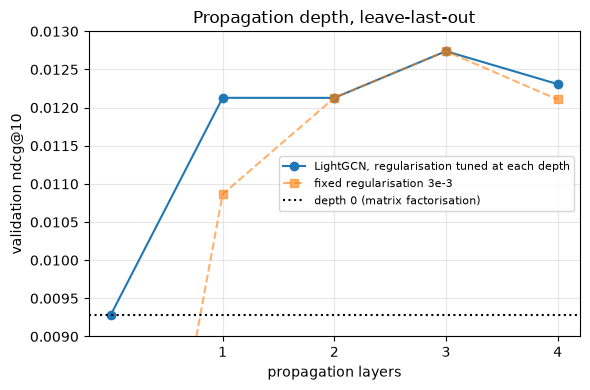

 n_layers  l2_reg  val_ndcg@10
        0 0.03000      0.00929
        1 0.01000      0.01213
        2 0.00300      0.01213
        3 0.00300      0.01274
        4 0.00100      0.01231


In [5]:
rows = []
for path in TUNING_CACHE.glob("LightGCN_last_out_L*_e300_s42.csv"):
    parts = path.stem.split("_")
    h = pd.read_csv(path).dropna(subset=["val_ndcg@10"])
    rows.append({"n_layers": int(parts[3][1:]), "l2_reg": float(parts[4][3:]),
                 "val_ndcg@10": h["val_ndcg@10"].max()})

surface = pd.DataFrame(rows)
best_per_depth = surface.loc[surface.groupby("n_layers")["val_ndcg@10"].idxmax()] \
                        .sort_values("n_layers")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(best_per_depth["n_layers"], best_per_depth["val_ndcg@10"],
        marker="o", label="LightGCN, regularisation tuned at each depth")
ax.plot(surface[surface.l2_reg == 3e-3].sort_values("n_layers")["n_layers"],
        surface[surface.l2_reg == 3e-3].sort_values("n_layers")["val_ndcg@10"],
        marker="s", linestyle="--", alpha=0.6,
        label="fixed regularisation 3e-3")

# Depth-0 anchor from the n_layers=0 regularisation sweep run through tune_one,
# on the same evaluator, interval and budget as depths 1-4 (audit D1).
ax.axhline(0.009288, color="black", linestyle=":", label="depth 0 (matrix factorisation)")

ax.set(xlabel="propagation layers", ylabel="validation ndcg@10",
       title="Propagation depth, leave-last-out")
ax.set_xticks([1, 2, 3, 4])
ax.set_ylim(0.009, 0.013)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "10_depth_curve.png", dpi=200)
plt.show()

print(best_per_depth.to_string(index=False, float_format="%.5f"))

The two curves differ only in how regularisation was handled. With a single value tuned
at three layers, depth appears to matter a great deal; with regularisation tuned at each
depth, one layer already captures most of the benefit and the remaining layers add little.
The gap between them at one layer is 11.6%, which is why the joint sweep was necessary.

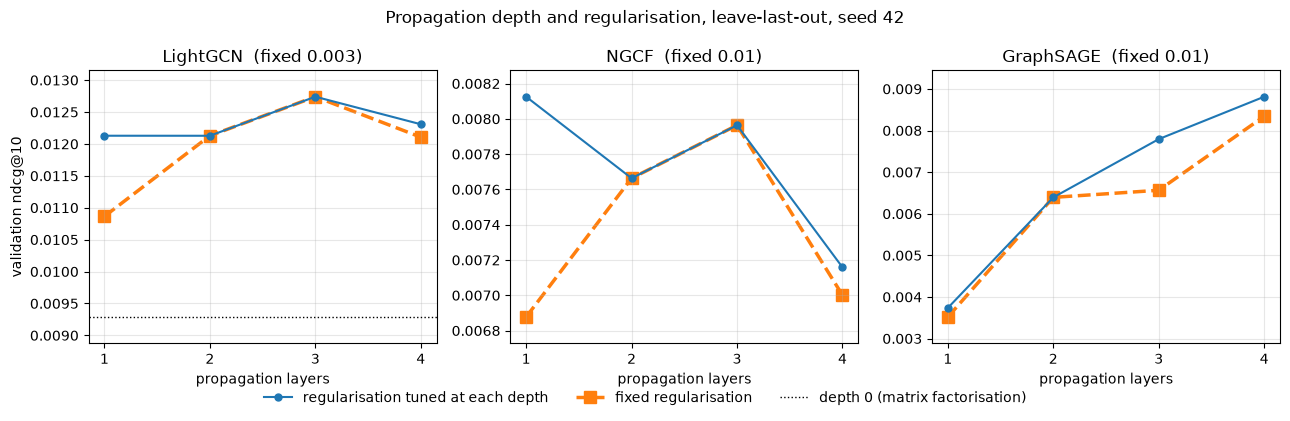

In [22]:
# Depth curves for all three graph models, tuned against fixed regularisation.

import re

FIXED = {"LightGCN": 3e-3, "NGCF": 1e-2, "GraphSAGE": 1e-2}


def depth_curves(model):
    rows = []
    for f in sorted(TUNING_CACHE.glob(f"{model}_last_out_L*_s42.csv")):
        n = f.name
        if model == "GraphSAGE":                      # adopted output configuration only
            if "normalise_outputFalse" not in n or "final_activationFalse" in n:
                continue
        elif "normalise_output" in n or "final_activation" in n:
            continue
        m = re.search(r"_L(\d+)_reg([0-9.e-]+)_", n)
        h = pd.read_csv(f).dropna(subset=["val_ndcg@10"])
        rows.append({"n_layers": int(m.group(1)), "l2_reg": float(m.group(2)),
                     "val": h["val_ndcg@10"].max()})
    d = pd.DataFrame(rows)
    tuned = d.loc[d.groupby("n_layers")["val"].idxmax()].sort_values("n_layers")
    fixed = d[np.isclose(d["l2_reg"], FIXED[model])].sort_values("n_layers")
    return d, tuned[tuned["n_layers"] > 0], fixed[fixed["n_layers"] > 0]


def plot_depth(ax, model, legend=False):
    grid, tuned, fixed = depth_curves(model)

    # fixed drawn first and heavier, so the tuned line stays visible where they coincide
    ax.plot(fixed["n_layers"], fixed["val"], marker="s", linestyle="--",
            color="tab:orange", linewidth=2.5, markersize=8, zorder=1,
            label="fixed regularisation")
    ax.plot(tuned["n_layers"], tuned["val"], marker="o", color="tab:blue",
            linewidth=1.5, markersize=5, zorder=2,
            label="regularisation tuned at each depth")

    values = list(tuned["val"]) + list(fixed["val"])

    if model == "LightGCN":                            # depth 0 is matrix factorisation
        base = grid.query("n_layers == 0")["val"].max()
        ax.axhline(base, color="black", linestyle=":", linewidth=1,
                   label="depth 0 (matrix factorisation)")
        values.append(base)

    lo, hi = min(values), max(values)
    pad = (hi - lo) * 0.12
    ax.set_ylim(lo - pad, hi + pad)

    ax.set(title=f"{model}  (fixed {FIXED[model]:g})",
           xlabel="propagation layers",
           xticks=sorted(fixed["n_layers"].unique()))
    ax.grid(alpha=0.3)
    if legend:
        ax.legend(fontsize=8, loc="best")


fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, model in zip(axes, ["LightGCN", "NGCF", "GraphSAGE"]):
    plot_depth(ax, model)
axes[0].set_ylabel("validation ndcg@10")

handles, labels = axes[0].get_legend_handles_labels()
order = [1, 0, 2]                                      # tuned, fixed, depth-0 reference
fig.legend([handles[i] for i in order], [labels[i] for i in order],
           loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))

fig.suptitle("Propagation depth and regularisation, leave-last-out, seed 42")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "10_depth_curve.png", dpi=200, bbox_inches="tight")
plt.show()

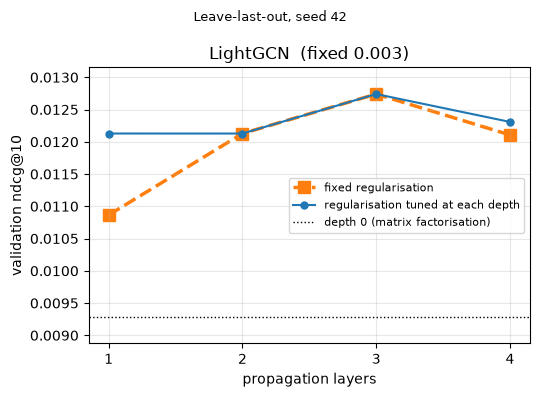

In [ ]:
# LightGCN depth curve alone

fig, ax = plt.subplots(figsize=(5.5, 4))
plot_depth(ax, "LightGCN", legend=True)
ax.set_ylabel("validation ndcg@10")
fig.suptitle("Leave-last-out, seed 42", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "10_depth_lightgcn.png", dpi=200, bbox_inches="tight")
plt.show()

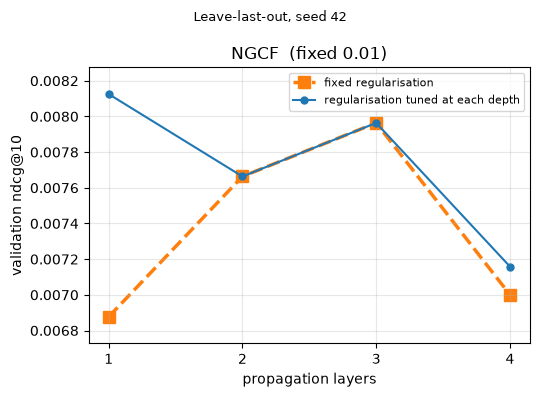

In [24]:
# NGCF depth curve alone

fig, ax = plt.subplots(figsize=(5.5, 4))
plot_depth(ax, "NGCF", legend=True)
ax.set_ylabel("validation ndcg@10")
fig.suptitle("Leave-last-out, seed 42", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "10_depth_ngcf.png", dpi=200, bbox_inches="tight")
plt.show()

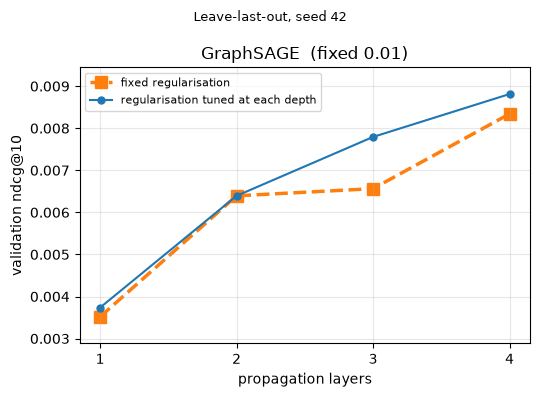

In [25]:
# GraphSAGE depth curve alone

fig, ax = plt.subplots(figsize=(5.5, 4))
plot_depth(ax, "GraphSAGE", legend=True)
ax.set_ylabel("validation ndcg@10")
fig.suptitle("Leave-last-out, seed 42", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "10_depth_graphsage.png", dpi=200, bbox_inches="tight")
plt.show()

In [33]:
mf_hist_path = TUNING_CACHE / "BPR-MF_last_out_L0_reg0.1_e300_s42.csv"

if not mf_hist_path.exists():
    d = data["last_out"]
    out = tr.train_bpr(
        md.MatrixFactorization(d["n_users"], d["n_items"], DIM, SEED),
        d["train"], d["n_items"], evaluator=tune_evaluators["last_out"],
        epochs=300, batch_size=BATCH, learning_rate=LR, l2_reg=0.10,
        sampling=SAMPLING, patience=10 ** 6, eval_every=5,
        selection_metric="ndcg@10", device=DEVICE, seed=SEED, verbose=False,
    )
    out["history"].to_csv(mf_hist_path, index=False)
    print(f"saved, best epoch {out['best_epoch']}")

else:
    print(f"cached: {mf_hist_path.name}")

cached: BPR-MF_last_out_L0_reg0.1_e300_s42.csv


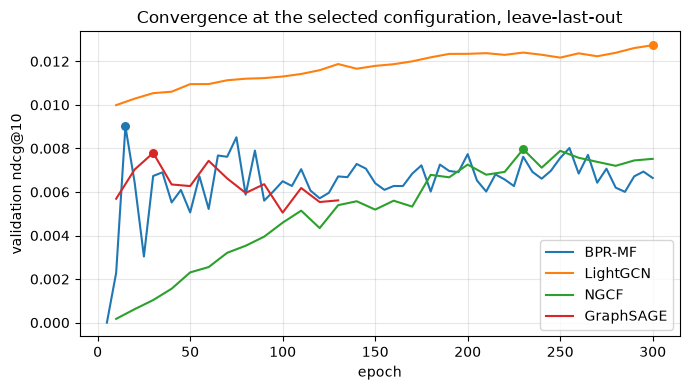

In [34]:
selected_tags = {
    "BPR-MF":    "BPR-MF_last_out_L0_reg0.1_e300_s42",
    "LightGCN":  "LightGCN_last_out_L3_reg0.003_e300_s42",
    "NGCF":      "NGCF_last_out_L3_reg0.01_e300_s42",
    "GraphSAGE": ("GraphSAGE_last_out_L3_reg0.003_e300"
                  "_final_activationTrue_normalise_outputFalse_s42"),
}

fig, ax = plt.subplots(figsize=(7, 4))
for name, tag in selected_tags.items():
    h = pd.read_csv(TUNING_CACHE / f"{tag}.csv").dropna(subset=["val_ndcg@10"])
    line, = ax.plot(h["epoch"], h["val_ndcg@10"], label=name)
    peak = h.loc[h["val_ndcg@10"].idxmax()]
    ax.scatter([peak["epoch"]], [peak["val_ndcg@10"]],
               color=line.get_color(), zorder=5, s=30)


ax.set(xlabel="epoch", ylabel="validation ndcg@10",
       title="Convergence at the selected configuration, leave-last-out")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "10_convergence.png", dpi=200)
plt.show()

LightGCN improves steadily throughout training and exceeds the best BPR-MF validation score at its first evaluation. NGCF starts near zero because its randomly initialised weight matrices disrupt the initial embedding structure, then recovers slowly but remains below the baseline. GraphSAGE peaks around epoch 30 before declining while training loss continues to fall, indicating overfitting. Early stopping halts training at epoch 130.

The curves are from the tuning runs at each model's selected configuration and are measured on the validation set.

## 7. Checks and saved results


In [35]:
by_model = final_summary.groupby(["protocol", "model"])["ndcg@10"].mean()
random_hr = 10 / data["last_out"]["n_items"]
metrics = final_summary[[c for c in final_summary if "@" in c]]

checks = {
    "all expected runs present":
        len(final_summary) == len(PROTOCOLS) * (3 * len(FINAL_SEEDS) + len(SEEDS)),
    "metrics all within [0, 1]":
        bool(((metrics >= 0) & (metrics <= 1)).all().all()),
    "hit rate increases with K":
        (final_summary["hit_rate@20"] >= final_summary["hit_rate@10"]).all(),
    "ndcg increases with K":
        (final_summary["ndcg@20"] >= final_summary["ndcg@10"] - 1e-9).all(),
    "every model beats random by 5x":
        (final_summary["hit_rate@10"] > 5 * random_hr).all(),
    "recall equals hit rate under leave-last-out (one relevant item)":
        np.allclose(
            final_summary.query("protocol == 'last_out'")["recall@10"],
            final_summary.query("protocol == 'last_out'")["hit_rate@10"]),
    "LightGCN beats BPR-MF under leave-last-out":
        by_model[("last_out", "LightGCN")] > by_model[("last_out", "BPR-MF")],
    "BPR-MF beats LightGCN under timestamp (the reversal)":
        by_model[("timestamp", "BPR-MF")] > by_model[("timestamp", "LightGCN")],
    "NGCF and GraphSAGE fall below BPR-MF under both protocols":
        all(by_model[(p, m)] < by_model[(p, "BPR-MF")]
            for p in PROTOCOLS for m in ["NGCF", "GraphSAGE"]),
    "BPR-MF has five seeds, graph models three":
        (final_summary.groupby(["protocol", "model"]).size()
         .unstack()["BPR-MF"] == len(SEEDS)).all(),
}

width = max(len(k) for k in checks)
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name:<{width}}")

assert all(checks.values()), [k for k, v in checks.items() if not v]
print(f"\nall {len(checks)} checks passed")

PASS  all expected runs present                                      
PASS  metrics all within [0, 1]                                      
PASS  hit rate increases with K                                      
PASS  ndcg increases with K                                          
PASS  every model beats random by 5x                                 
PASS  recall equals hit rate under leave-last-out (one relevant item)
PASS  LightGCN beats BPR-MF under leave-last-out                     
PASS  BPR-MF beats LightGCN under timestamp (the reversal)           
PASS  NGCF and GraphSAGE fall below BPR-MF under both protocols      
PASS  BPR-MF has five seeds, graph models three                      

all 10 checks passed


In [ ]:
summary = {
    "notebook": "10_hyperparameter_tuning",
    "subset": SUBSET,
    "protocols": PROTOCOLS,
    "seeds": {"graph_models": FINAL_SEEDS, "BPR-MF": SEEDS},
    "training": {
        "epochs": 300, "dim": DIM, "batch_size": BATCH, "learning_rate": LR,
        "sampling": SAMPLING, "patience_epochs": 100,
        "eval_every": {"BPR-MF": 2, "graph_models": 10},
        "selection_metric": "ndcg@10",
    },
    "tuning": {
        "method": {
            "NGCF, GraphSAGE": "coordinate descent: regularisation at the default "
                               "depth, then depth at the selected regularisation",
            "LightGCN": "staggered grid over depth and regularisation, three "
                        "regularisation values at each of four depths",
        },
        "runs": len(list(TUNING_CACHE.glob("*.csv"))),
        "selected": BEST,
    },
    "propagation_depth_last_out": {
        "note": "validation ndcg@10 on the tuning evaluator, seed 42, "
                "regularisation tuned separately at each depth",
        "depth_0_anchor": {
            "l2_reg": float(depth_zero.loc[depth_zero["val_ndcg@10"].idxmax(), "l2_reg"]),
            "val_ndcg@10": float(depth_zero["val_ndcg@10"].max()),
        },
        "by_depth": depth_tuned.loc[
            depth_tuned.groupby("n_layers")["val_ndcg@10"].idxmax()
        ][["n_layers", "l2_reg", "val_ndcg@10"]].to_dict(orient="records"),
    },
    "sampler_ablation": sampler_ablation.to_dict(orient="records"),
    "results_ndcg@10": {
        f"{p} / {m}": {"mean": float(g["ndcg@10"].mean()),
                       "std": float(g["ndcg@10"].std()),
                       "seeds": int(len(g))}
        for (p, m), g in final_summary.groupby(["protocol", "model"])
    },
}

with open(RESULTS_DIR / "10_summary.json", "w") as fh:
    json.dump(summary, fh, indent=2)

print(json.dumps(summary["results_ndcg@10"], indent=2))

{
  "last_out / BPR-MF": {
    "mean": 0.006404829304665327,
    "std": 0.0006876834153527869,
    "seeds": 5
  },
  "last_out / GraphSAGE": {
    "mean": 0.004254855991651614,
    "std": 0.00019514322595427173,
    "seeds": 3
  },
  "last_out / LightGCN": {
    "mean": 0.008124100354810556,
    "std": 6.570082934119323e-05,
    "seeds": 3
  },
  "last_out / NGCF": {
    "mean": 0.004245576603959004,
    "std": 0.00012959728336667592,
    "seeds": 3
  },
  "timestamp / BPR-MF": {
    "mean": 0.004649654775857925,
    "std": 0.0003995251070947537,
    "seeds": 5
  },
  "timestamp / GraphSAGE": {
    "mean": 0.0013429514753321807,
    "std": 0.0001430794665694772,
    "seeds": 3
  },
  "timestamp / LightGCN": {
    "mean": 0.001575416885316372,
    "std": 0.0001975268252474575,
    "seeds": 3
  },
  "timestamp / NGCF": {
    "mean": 0.0015011874105160434,
    "std": 0.00010298030941433337,
    "seeds": 3
  }
}


## Findings

**Under leave-last-out, LightGCN improves on matrix factorisation by 27%** - NDCG@10
0.00812 +/- 0.00007 against 0.00641 +/- 0.00069, with no overlap between the ranges.
NGCF and GraphSAGE both fall below the baseline. LightGCN does not, however, beat
ItemKNN (0.00948), so the strongest method under this protocol is item-item neighbourhood
collaborative filtering rather than any graph neural network.

**Under the timestamp protocol the ranking reverses completely.** BPR-MF reaches
0.00465 +/- 0.00040 against LightGCN's 0.00158 +/- 0.00020, a factor of 2.9, and every
graph model also falls below ItemKNN. The reversal is not an artefact of the test
population: it is already present on validation, where all models are scored on identical
users. Whether graph convolution helps on this data therefore depends on which evaluation
protocol is used, which is the central result of this notebook.

**Propagation saturates at the first hop.** With regularisation tuned separately at each
depth, one layer gives +27% over BPR-MF, three give +34%, and four fall back to +29%. A
fixed-regularisation sweep understated the one-layer result by 11.6% and made depth look
far more important than it is. With about seven interactions per user there is little
informative signal two or three hops away.

**Only the simplified graph model works.** NGCF and GraphSAGE lose to matrix
factorisation under both protocols, which supports LightGCN's argument that feature
transformation and nonlinear activation are unnecessary machinery. That claim is credible
here because Notebook 09 shows the same NGCF implementation reproducing its published
Gowalla result to within 2.2%; the failure belongs to the data regime, not the code.

**Two methodological findings.** Comparing hyperparameters at a fixed epoch budget
confounds regularisation strength with convergence speed. And checkpoint granularity has
to be scaled to a model's convergence timescale: evaluating BPR-MF every 10 epochs rather
than every 2 selected a checkpoint scoring marginally higher on validation and 30% worse
on test, which would have overstated LightGCN's advantage as 67% rather than 27%.

The ordering is almost identical under NDCG@10, HitRate@10 and Recall@20,
so no conclusion depends on the choice of metric.